
# **SEMESTER PROJECT DELIVERABLE 2 (ML ENGINE)**

## **Group:** 4

## **Members:**

##### 191231 - Patrick Mungai

##### 192082 - DavidTelios Muriithi


## **Model:** Logistic Regression

## **Task:** Resume to job-category recommendation (multi-class text classification used for top-k ranking).

## **Dataset:** Kaggle Resume Dataset - [https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset]()

In [2]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
matches = list(Path(".").rglob("Resume.csv"))
if not matches:
    raise FileNotFoundError("Resume.csv not found. Download the Kaggle Resume Dataset (link in README), unzip it, and place Resume.csv inside the 'Resume' folder.")
CSV_PATH = matches[0]
print("Using:", CSV_PATH)

Using: Resume.csv


In [3]:
import os

print("CSV path:", CSV_PATH)
print("File exists:", os.path.exists(CSV_PATH))

if os.path.exists(CSV_PATH):
    print("File size:", os.path.getsize(CSV_PATH), "bytes")

CSV path: Resume.csv
File exists: True
File size: 56273235 bytes


In [4]:
raw = pd.read_csv(CSV_PATH)
print("Shape:", raw.shape)
print(raw.dtypes, "\n")
print("Missing values:\n", raw.isnull().sum(), "\n")
print("Number of classes:", raw["Category"].nunique())
raw.head(3)

Shape: (2484, 4)
ID              int64
Resume_str     object
Resume_html    object
Category       object
dtype: object 

Missing values:
 ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64 

Number of classes: 24


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [5]:
df = raw.copy()
text = df["Resume_str"].fillna("")

print("Empty/near-empty (<=200 chars):", (text.str.strip().str.len()<= 200).sum())
print("Exact duplicate texts:", text.duplicated().sum())
print("Contain 'Company Name' placeholder:", text.str.contains("Company Name").sum())
print("Contain encoding junk:", text.str.contains("Â|ï¼|â€|Ã", regex = True).sum())
print("Shortest lengths:", sorted(text.str.len())[:5])
print("Longest length:", text.str.len().max())
print("\nHow a resume opens:\n", text.iloc[0][:150])

Empty/near-empty (<=200 chars): 1
Exact duplicate texts: 2
Contain 'Company Name' placeholder: 2483
Contain encoding junk: 3
Shortest lengths: [21, 881, 985, 995, 1033]
Longest length: 38842

How a resume opens:
          HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in H


In [6]:
df = raw.copy()
log = []
def step(name, before, after):
    log.append({"step": name, "rows_before": before, "rows_after": after})

# Drop the redundant HTML column
df = df.drop(columns=["Resume_html"])

# Drop empty resumes
n = len(df)
df["Resume_str"] = df["Resume_str"].fillna("")
df = df[df["Resume_str"].str.strip().str.len() > 200]
step(" Drop empty (<=200 chars)", n, len(df))

# Drop duplicate texts
n = len(df)
df = df.drop_duplicates(subset="Resume_str", keep="first")
step("Drop duplicates", n, len(df))

# Keeping the original for EDA
df["raw_text"] = df["Resume_str"]
df = df.reset_index(drop = True)
pd.DataFrame(log)

,step,rows_before,rows_after
0,Drop empty (<=200 chars),2484,2483
1,Drop duplicates,2483,2481


In [7]:
def fix_encoding_junk(text):
    for bad in ["Â", "ï¼", "â€“", "â€™", "Ã"]:
        text = text.replace(bad, " ")
    return text

def strip_title(text):
    m = re.match(r"^\s*(?:[A-Z0-9/][A-Z0-9/&,\-\.\(\)']*\s+)+", text)
    s = text[m.end():] if m else text
    return s if len(s.strip()) > 200 else text

def clean(text):
    text = strip_title(text)
    text = fix_encoding_junk(text)
    text = text.replace("Company Name", " ").replace("City, State", " ")
    text = re.sub(r"[^A-Za-z+#\s]", " ", text) # Keeps letters, + and #
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df["text"] = df["Resume_str"].apply(clean)
n = len(df)
df = df[df["text"].str.len() > 100].reset_index(drop = True)
step(" Drop resumes empty after cleaning (<=100 chars)", n, len(df))
pd.DataFrame(log)


,step,rows_before,rows_after
0,Drop empty (<=200 chars),2484,2483
1,Drop duplicates,2483,2481
2,Drop resumes empty after cleaning (<=100 chars),2481,2481


In [8]:
print("Cleaned dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Cleaned dataset shape: (2481, 5)
Columns: ['ID', 'Resume_str', 'Category', 'raw_text', 'text']


,ID,Resume_str,Category,raw_text,text
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,summary dedicated customer service manager wit...
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...",HR,"HR SPECIALIST, US HR OPERATIONS ...",summary versatile media professional with back...
2,33176873,HR DIRECTOR Summary Over 2...,HR,HR DIRECTOR Summary Over 2...,summary over years experience in recruiting pl...
3,27018550,HR SPECIALIST Summary Dedica...,HR,HR SPECIALIST Summary Dedica...,summary dedicated driven and dynamic with over...
4,17812897,HR MANAGER Skill Highlights ...,HR,HR MANAGER Skill Highlights ...,skill highlights hr skills hr department start...


In [9]:
# 4. Exploratory Data Analysis (EDA)

#This section examines the cleaned resume dataset

Number of categories: 24
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   117
FITNESS                   117
SALES                     116
AVIATION                  116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


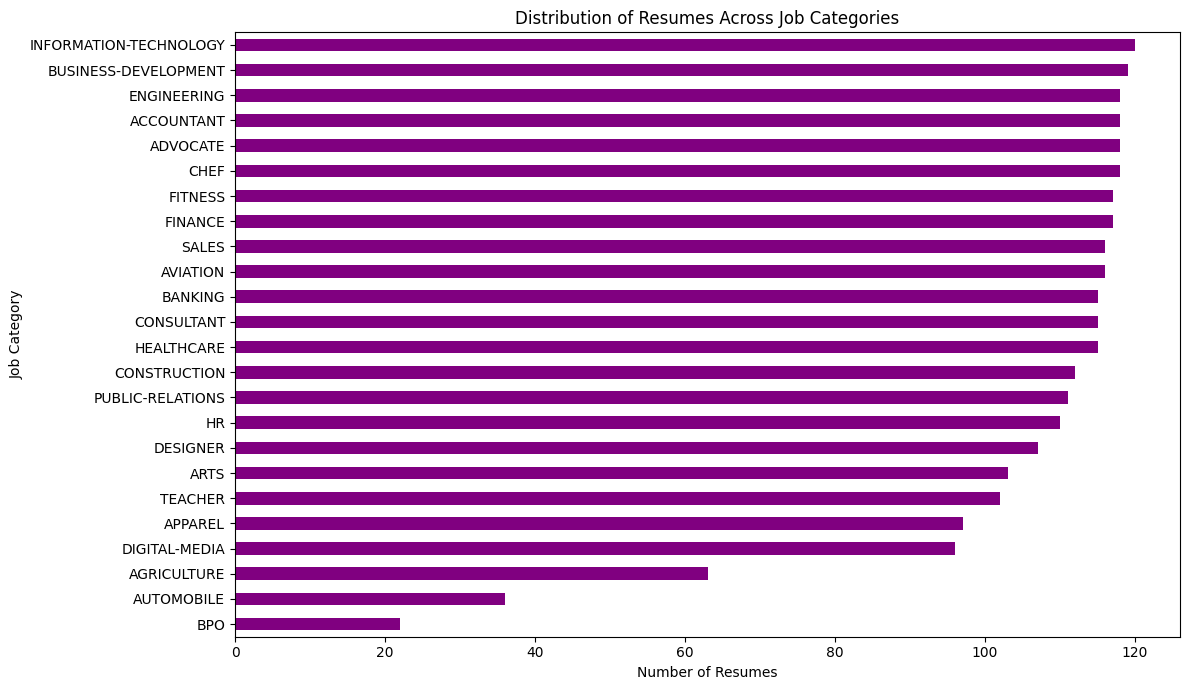

In [10]:
#EDA 1, Distribution of job catgeories
# How many CVs/resumes belong to each job category?
#Logistic regression needs examples from each category to learn how to distinguish them.
category_counts = df['Category'].value_counts() #how many times each unique category appears(no of resumes)
print("Number of categories:", df["Category"].nunique()) #getting the number of distinct job categories
print(category_counts)

plt.figure(figsize=(12,7))
category_counts.sort_values().plot(
    kind="barh" ,#horizontal barchart
    color="purple"
)
plt.title("Distribution of Resumes Across Job Categories")
plt.xlabel("Number of Resumes")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()



count    2481.000000
mean      777.355502
std       365.534524
min        93.000000
25%       620.000000
50%       725.000000
75%       894.000000
max      5117.000000
Name: word_count, dtype: float64


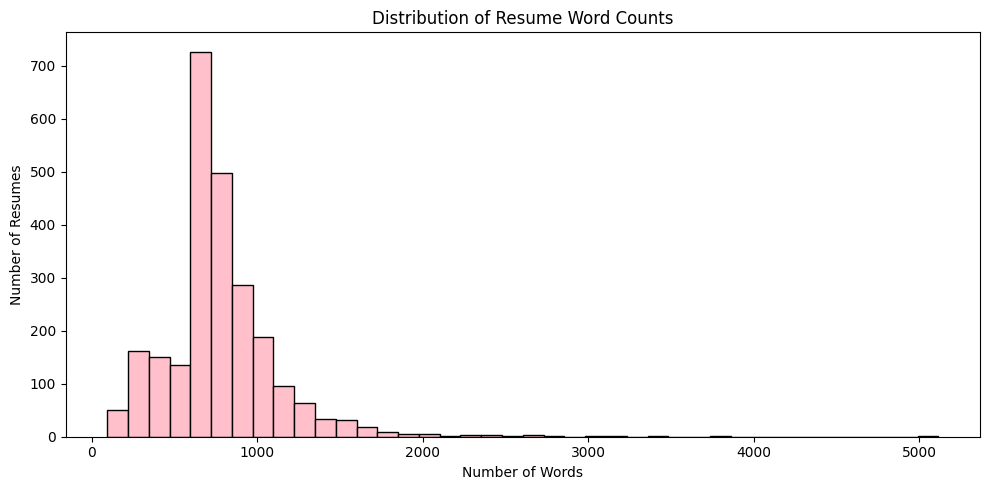

In [11]:
#EDA 2- Resume length analysis
df["word_count"] =df["text"].str.split().str.len()
print(df["word_count"].describe())
plt.figure(figsize=(10,5))
plt.hist(
    df["word_count"],
    bins=40,
    color="pink",
    edgecolor="black"
)
plt.title("Distribution of Resume Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Resumes")
plt.tight_layout()
plt.show()

state          16142
city           15054
management     12151
sales           8113
customer        7879
skills          7721
business        7713
new             6403
service         6167
team            6062
training        5629
experience      5626
development     5598
project         5302
work            4811
marketing       4439
information     4408
financial       4205
office          4163
manager         4128
dtype: int64


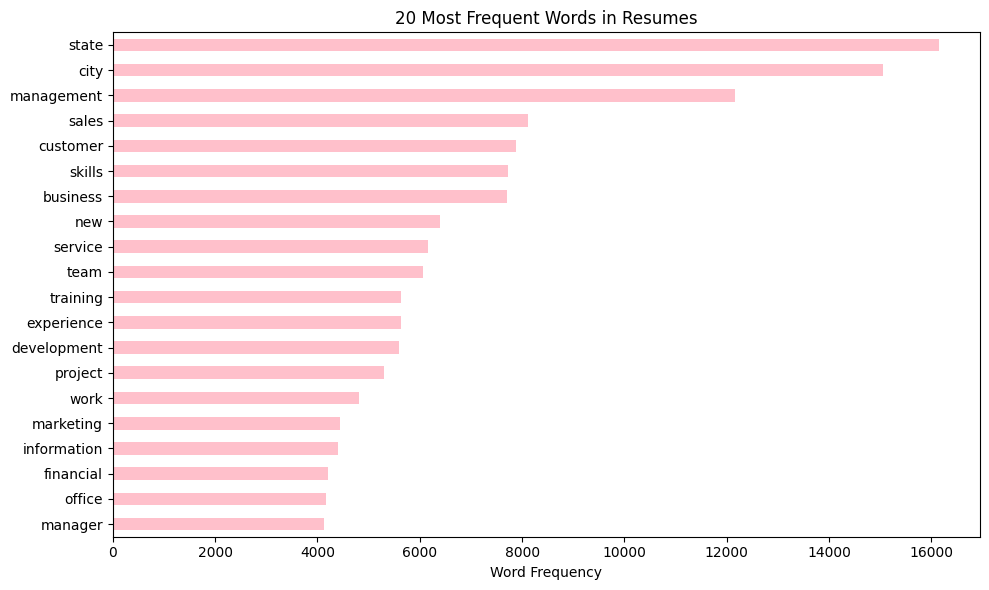

In [12]:
#EDA 3 Most frequent words across the CVs

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)


word_matrix = vectorizer.fit_transform(df["text"])

word_counts = np.asarray(
    word_matrix.sum(axis=0)
).flatten()

word_freq = pd.Series(
    word_counts,
    index=vectorizer.get_feature_names_out()
).sort_values(ascending=False)

print(word_freq)

plt.figure(figsize=(10, 6))

word_freq.sort_values().plot(
    kind="barh",
    color="pink"  # Changed from 'mediumpink' to valid matplotlib 'pink'
)

plt.title("20 Most Frequent Words in Resumes")

plt.xlabel("Word Frequency")
plt.tight_layout()
plt.show()

management       2118
sales            1311
communication    1295
leadership       1026
excel             958
marketing         870
accounting        559
sql               178
java               67
python             40
dtype: int64


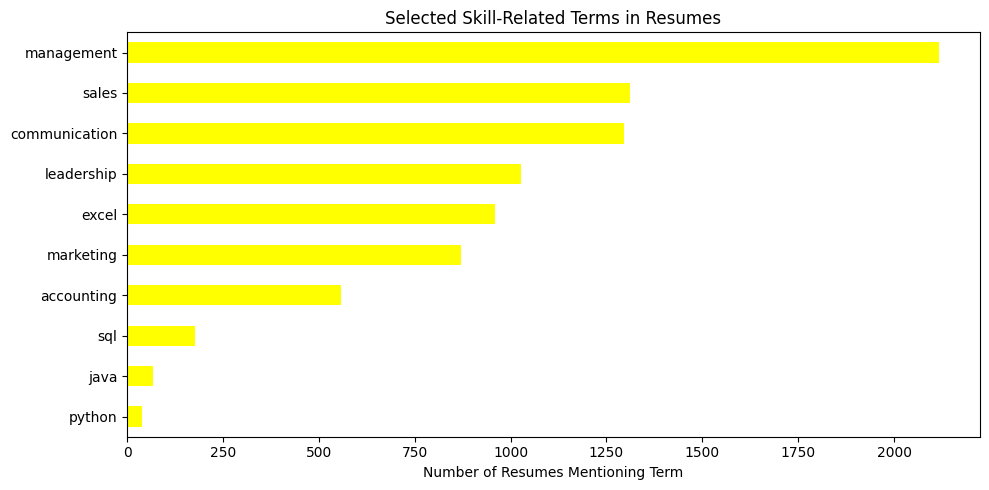

In [13]:
#EDA 4, how often do selected skills appear in resumes

skills = [
    "python",
    "java",
    "sql",
    "excel",
    "communication",
    "leadership",
    "management",
    "marketing",
    "accounting",
    "sales"
]

skill_counts = {}

for skill in skills:
    pattern = r"\b" + re.escape(skill) + r"\b"

    skill_counts[skill] = (
        df["text"].str.contains(
            pattern,
            regex=True,
            na=False
        ).sum()
    )

skill_freq = pd.Series(
    skill_counts
).sort_values(ascending=False)

print(skill_freq)

plt.figure(figsize=(10, 5))

skill_freq.sort_values().plot(
    kind="barh",
    color="yellow"
)

plt.title("Selected Skill-Related Terms in Resumes")
plt.xlabel("Number of Resumes Mentioning Term")
plt.tight_layout()
plt.show()

Category
SALES                     665.0
TEACHER                   688.5
FITNESS                   689.0
DESIGNER                  700.0
DIGITAL-MEDIA             705.5
ADVOCATE                  709.0
ARTS                      710.0
BUSINESS-DEVELOPMENT      712.0
BANKING                   713.0
ACCOUNTANT                714.0
HR                        718.0
AUTOMOBILE                724.0
FINANCE                   727.0
APPAREL                   728.0
AVIATION                  729.0
CHEF                      730.0
PUBLIC-RELATIONS          738.0
ENGINEERING               745.5
CONSTRUCTION              752.0
HEALTHCARE                753.0
AGRICULTURE               757.0
CONSULTANT                797.0
INFORMATION-TECHNOLOGY    810.0
BPO                       839.5
Name: word_count, dtype: float64


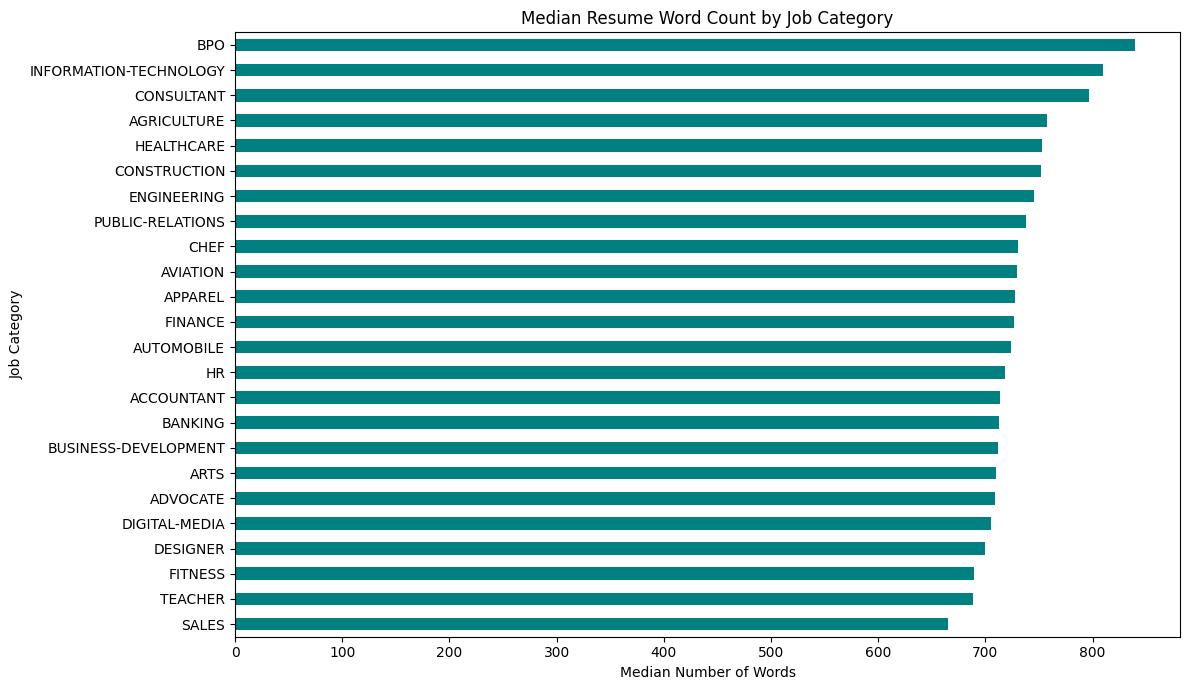

In [14]:
#EDA 5, do resumes in different job categories vary in length?

category_lengths = (
    df.groupby("Category")["word_count"]
    .median()
    .sort_values()
)

print(category_lengths)

plt.figure(figsize=(12, 7))

category_lengths.plot(
    kind="barh",
    color="teal"
)

plt.title("Median Resume Word Count by Job Category")
plt.xlabel("Median Number of Words")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

## Summary of EDA Findings

### Observation 1: Job Category Distribution

The cleaned dataset contains 2,481 resumes distributed across 24 job categories, Information Technology has approximately 120 resumes, while BPO has only 22. This indicates class imbalance, which may affect the model's ability to classify less-represented categories. We could use Stratified train/test splitting and per-class evaluation.

### Observation 2: Variation in Resume lengths
The average resume contains approximately 777 words, resume lengths range from 93 to 5,117 words. The presence of exceptionally long resumes suggests a right-skewed distribution, considerable during text feature extraction.

### Observation 3: Frequent words include potentially irrelevant terms
The most frequent words include "state" (16,142 occurrences), "city" (15,054), and "management" (12,151). Terms such as state and city may reflect address info.

###Observation 4: Differences in skill-related term frequencies

The selected skill analysis shows that management appears in 2,118 resumes, communication in 1,295, and leadership in 1,026. Technical terms such as SQL (178), Java (67), and Python (40) appear less frequently. This suggests that the dataset contains a broad range of professional vocabulary, with selected general business terms more common than programming terms. Term frequency alone does not indicate skill proficiency or job suitability.

### Observation 5: Resume length varies by job category
Median resume lengths differ between job categories. BPO has a median of 839.5 words, Information Technology 810 words, and Sales 665 words. These differences suggest that resume descriptions vary across professional fields but should not be interpreted as a measure of applicant quality.


In [15]:
%pip install pandas numpy scikit-learn matplotlib seaborn nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\david\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

# Load dataset
df = pd.read_csv('Resume.csv')
print(f"Dataset Shape: {df.shape}")
print(f"Number of Unique Categories: {df['Category'].nunique()}")

Dataset Shape: (2484, 4)
Number of Unique Categories: 24


In [17]:
# 1. Feature & Target Selection
X = df['Resume_str']
y = df['Category']

# 2. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 4. Base Model Definition (Logistic Regression with Regularization)
base_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)

# 5. 5-Fold Stratified Cross-Validation Verification
cv_scores = cross_val_score(base_model, X_train_tfidf, y_train, cv=5, scoring='f1_weighted')
print(f"Base Model 5-Fold CV Weighted F1-Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# 6. Fit Base Model & Evaluate on Held-Out Test Set
base_model.fit(X_train_tfidf, y_train)
y_pred_base = base_model.predict(X_test_tfidf)

print("\n--- Base Model (Logistic Regression) Test Performance ---")
print(classification_report(y_test, y_pred_base))

Base Model 5-Fold CV Weighted F1-Score: 0.6321 (+/- 0.0237)

--- Base Model (Logistic Regression) Test Performance ---
                        precision    recall  f1-score   support

            ACCOUNTANT       0.65      0.83      0.73        24
              ADVOCATE       0.35      0.54      0.43        24
           AGRICULTURE       1.00      0.46      0.63        13
               APPAREL       0.67      0.21      0.32        19
                  ARTS       0.46      0.29      0.35        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.85      0.71      0.77        24
               BANKING       0.79      0.65      0.71        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.54      0.92      0.68        24
                  CHEF       0.81      0.71      0.76        24
          CONSTRUCTION       0.77      0.77      0.77        22
            CONSULTANT       0.50      0.22     

In [18]:
# Define alternative models for comparative validation
models = {
    'Logistic Regression (Base)': LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    'Multinomial Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Linear SVM': LinearSVC(C=1.0, random_state=42)
}

results = []

for name, model in models.items():
    # Evaluate via 5-Fold Cross Validation
    cv_acc = cross_val_score(model, X_train_tfidf, y_train, cv=5, scoring='accuracy').mean()
    
    # Fit and evaluate on Test Set
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    
    test_acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    
    results.append({
        'Model': name,
        '5-Fold CV Accuracy': round(cv_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'Macro F1-Score': round(macro_f1, 4),
        'Weighted F1-Score': round(weighted_f1, 4)
    })

# Render Comparison Table in VS Code Notebook
results_df = pd.DataFrame(results)
display(results_df)

,Model,5-Fold CV Accuracy,Test Accuracy,Macro F1-Score,Weighted F1-Score
0,Logistic Regression (Base),0.6502,0.6559,0.5959,0.6401
1,Multinomial Naive Bayes,0.5576,0.5594,0.4776,0.5222
2,Random Forest,0.7081,0.7284,0.6478,0.7007
3,Linear SVM,0.7076,0.7364,0.6981,0.7306


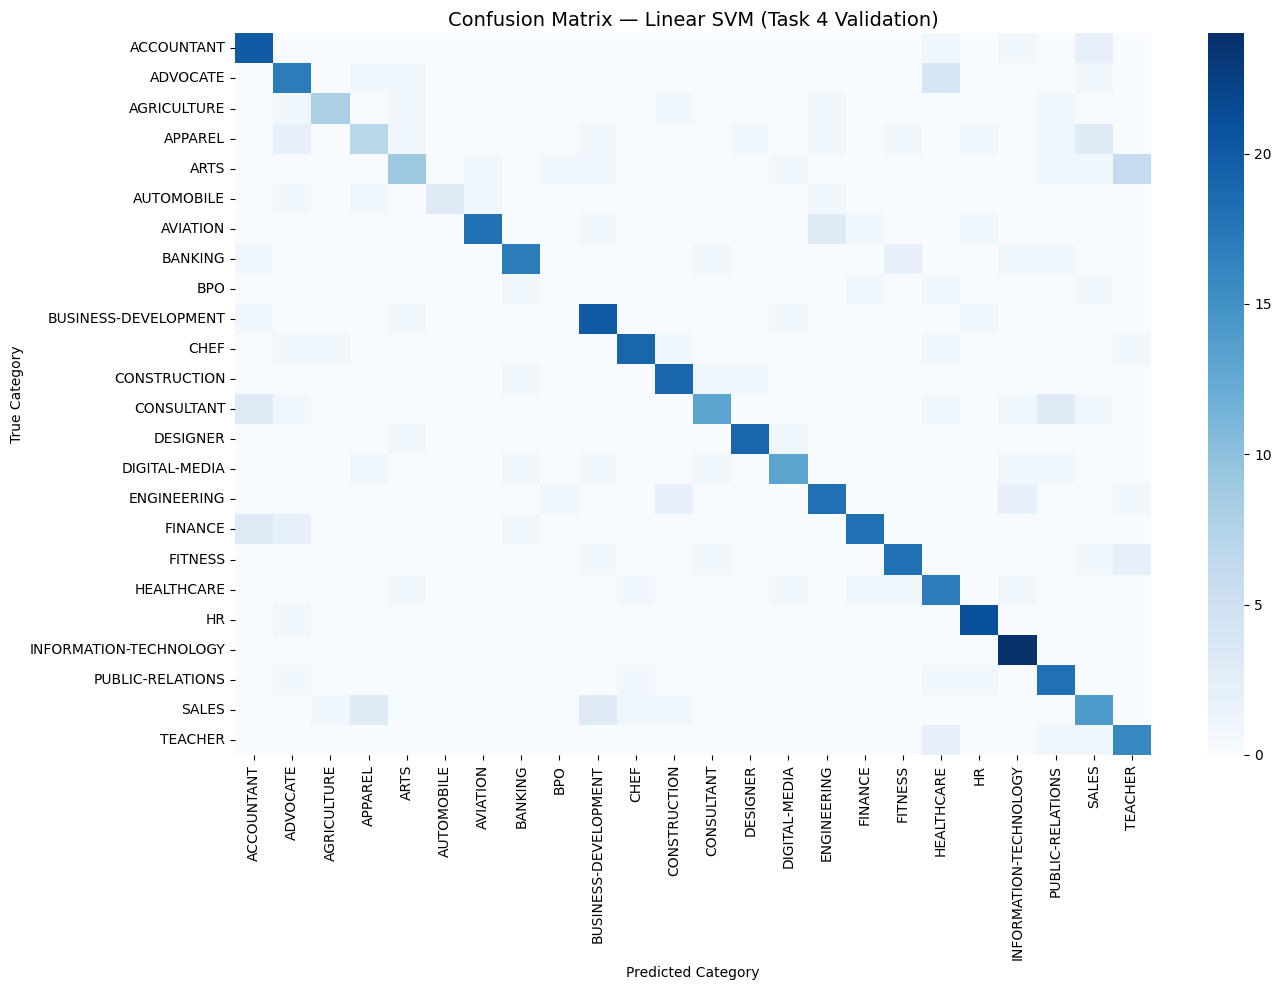

In [19]:
# Plot Confusion Matrix for the Best Performing Model (Linear SVM / Base Model)
best_model = LinearSVC(C=1.0, random_state=42)
best_model.fit(X_train_tfidf, y_train)
y_pred_best = best_model.predict(X_test_tfidf)

plt.figure(figsize=(14, 10))
cm = confusion_matrix(y_test, y_pred_best, labels=best_model.classes_)
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.title('Confusion Matrix — Linear SVM (Task 4 Validation)', fontsize=14)
plt.xlabel('Predicted Category')
plt.ylabel('True Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()